Adım 1: Veri tabanı ve tablo bağlantısı

Adım 2: Ham EKG sinyallerinin okunması

Adım 3: Sinyal filtreleme ve temizleme

Adım 4: Kalite kontrol (Varyans filtresi)

Adım 5: R-Tepe (R-Peak) tespiti

Adım 6: Siyam ağı için hizalama (Segmentation)

Adım 7: Genlik normalizasyonu (Min-Max Scaling)

Adım 8: ThreadPool ile paralel işlem (Multitasking)

Adım 9: Kalıcı depolama (NumPy Save)

# TODO:
"""
🚀 Neden Bu Mimari Çok Başarılı?
Güvenlik Katmanlaşması:

Model A (0.8+): Senin "Altın Standardın". En yüksek hassasiyete sahip. Kimlik doğrulama için kullanılacak ana model.

Model B (0.5 - 0.8): "Esnek Model". Gürültüyü tolere edebilen, ancak Model A kadar keskin olmayan ara model.

Model C (0.5-): Bu grup bir "Eğitim seti" değil, bir "Reddetme Seti" olmalı. Bu seviyedeki sinyalleri eğitmek, sistemi yanıltmaya (false acceptance) neden olabilir.

Jüriyi Büyüleyecek "Akıllı Geçiş" Mekanizması:
Sistemine bir "Decision Engine" (Karar Mekanizması) ekleyebilirsin:

Kullanıcı EKG'sini gönderdi.

Önce nk.ecg_quality() çalışır.

Skor 0.8'den büyükse Model A'ya yönlendirilir.

Skor 0.5 - 0.8 arasındaysa Model B'ye yönlendirilir.

Skor 0.5'ten düşükse sistem kullanıcıya "Sinyal çok zayıf, lütfen saatini sıkılaştır ve hareketsiz kal" uyarısı verir.

🛠️ İzleyeceğin Yol Haritası
Bu mimariyi kurmak için şu modüler adımları takip etmelisin:

Veri Kümeleme (Data Partitioning):
02_preprocessing_and_pairs.ipynb notebook'unda veriyi tüm sinyallerin kalite skorlarını hesaplayarak şu üç klasöre ayır:

/data/train/high_quality/

/data/train/medium_quality/

/data/train/low_quality/ (Bunu eğitime alma, sadece test için sakla)

Siyam Ağlarını Eğitme:

Eğitim 1: Model A'yı sadece high_quality çiftleriyle eğit.

Eğitim 2: Model B'yi hem high_quality hem de medium_quality karışımıyla (Fine-tuning yaparak) eğit.

Performans Kıyaslaması:
Jüriye şunu göstereceksin: "Model A, yüksek kaliteli veride %99 doğruluk veriyor; Model B ise orta kaliteli veride %92 doğrulukla güvenliği korumaya devam ediyor."

"""

In [ ]:
!pip install wfdb neurokit2 tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 98.2 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.


In [ ]:
# Sistem ve Dosya Yönetimi
import os

# Veri Manipülasyonu ve Matematiksel İşlemler
import numpy as np
import pandas as pd

# Sinyal İşleme (EKG Temizleme ve Analiz)
import wfdb
import neurokit2 as nk

# İlerleme Çubuğu (Uzun döngüleri takip etmek için)
from tqdm import tqdm

# Görselleştirme (Ara kontroller için)
import matplotlib.pyplot as plt
import seaborn as sns

import itertools
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed
from collections import Counter

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
drive_base_path = '/content/drive/MyDrive/BeatKrypt/'
data_path = os.path.join(drive_base_path)
csv_path = os.path.join(data_path, 'ptbxl_database.csv')

QUALITY_HIGH_THRESHOLD = 0.75
QUALITY_MEDIUM_THRESHOLD = 0.50

# Örnekleme frekansı (Edge AI hedefi için)
sample_rate = 100

print(f"✓ Veri seti yolu: {csv_path}")

✓ Veri seti yolu: /content/drive/MyDrive/BeatKrypt/ptbxl_database.csv


In [ ]:
ptbxl = pd.read_csv(csv_path)

In [ ]:
# Her hastanın kaç kaydı olduğunu sayalım
patient_record_counts = ptbxl['patient_id'].value_counts().reset_index()
patient_record_counts.columns = ['patient_id', 'record_count']

# 3 veya daha fazla kaydı olan hastaları filtreleyelim
positive_patient_ids_df = patient_record_counts[patient_record_counts['record_count'] >= 3]

# Pozitif Çift Havuzu: 3 veya daha fazla kaydı olan hastaların ID'leri
positive_pair_patient_ids = positive_patient_ids_df['patient_id'].tolist()

# Negatif Çift Havuzu: Tüm benzersiz hasta ID'leri
negative_pair_patient_ids = ptbxl['patient_id'].unique().tolist()

print(f"Pozitif Çift Havuzu için Hasta ID sayısı: {len(positive_pair_patient_ids)}")
print(f"Negatif Çift Havuzu için Hasta ID sayısı: {len(negative_pair_patient_ids)}")

Pozitif Çift Havuzu için Hasta ID sayısı: 521
Negatif Çift Havuzu için Hasta ID sayısı: 18869


In [ ]:
output_dir = os.path.join(drive_base_path, 'processed_data_split')
for tier in ['high', 'medium']:
    os.makedirs(os.path.join(output_dir, tier), exist_ok=True)

In [ ]:
positive_pairs = []

pure_positives_df = ptbxl[ptbxl['patient_id'].isin(positive_pair_patient_ids)]

for patient_id in tqdm(positive_pair_patient_ids, desc="Pozitif Çiftler Oluşturuluyor"):
    patient_records = pure_positives_df[pure_positives_df['patient_id'] == patient_id]['filename_lr'].tolist()

    for rec1, rec2 in itertools.combinations(patient_records, 2):
        positive_pairs.append({
            'left_filename': rec1,
            'right_filename': rec2,
            'left_patient_id': patient_id,
            'right_patient_id': patient_id,   # pozitifte ikisi de aynı hasta
            'label': 1.0
        })

positive_pairs_df = pd.DataFrame(positive_pairs)
total_positive_count = len(positive_pairs_df)
print(f"\n✓ Toplam oluşturulan pozitif çift sayısı: {total_positive_count}")

Pozitif Çiftler Oluşturuluyor: 100%|██████████| 521/521 [00:01<00:00, 458.46it/s]


✓ Toplam oluşturulan pozitif çift sayısı: 2684


In [ ]:
negative_pairs = []

pure_negatives_df = ptbxl[ptbxl['patient_id'].isin(negative_pair_patient_ids)]
target_negative_count = total_positive_count

patient_to_files = pure_negatives_df.groupby('patient_id')['filename_lr'].apply(list).to_dict()
unique_patients = np.array(list(patient_to_files.keys()))

rng = np.random.default_rng(42)
left_patients = rng.choice(unique_patients, size=target_negative_count)

for left_patient in tqdm(left_patients, desc="Dengeli Negatif Çiftler Oluşturuluyor"):
    right_patient = rng.choice(unique_patients)
    while right_patient == left_patient:
        right_patient = rng.choice(unique_patients)

    left_filename = rng.choice(patient_to_files[left_patient])
    right_filename = rng.choice(patient_to_files[right_patient])

    negative_pairs.append({
        'left_filename': left_filename,
        'right_filename': right_filename,
        'left_patient_id': left_patient,
        'right_patient_id': right_patient,
        'label': 0.0
    })

negative_pairs_df = pd.DataFrame(negative_pairs)
print(f"\n✓ Toplam oluşturulan negatif çift sayısı: {len(negative_pairs_df)}")

Dengeli Negatif Çiftler Oluşturuluyor: 100%|██████████| 2684/2684 [00:00<00:00, 5067.52it/s]


✓ Toplam oluşturulan negatif çift sayısı: 2684


In [ ]:
# 1. İki havuzu tek bir büyük DataFrame'de birleştir
all_pairs_df = pd.concat([positive_pairs_df, negative_pairs_df], ignore_index=True)

# 2. Satırları rastgele karıştır
all_pairs_df = all_pairs_df.sample(frac=1, random_state=42).reset_index(drop=True)

# 🌟 1. ADIM: KOLON TİPLERİNİ SAF SKELETLERE ZORLUYORUZ
all_pairs_df['left_filename'] = all_pairs_df['left_filename'].astype(str)
all_pairs_df['right_filename'] = all_pairs_df['right_filename'].astype(str)
all_pairs_df['label'] = all_pairs_df['label'].astype(float)

# 3. Sonuçları doğrula
print(f"✓ Eşleştirme tablosu başarıyla birleştirildi ve karıştırıldı!")
print(f"Toplam Çift Sayısı: {len(all_pairs_df)}")
print(f"\nSınıf Dağılımı:\\n{all_pairs_df['label'].value_counts()}")

# İlk 5 satıra göz atalım
all_pairs_df.head()

✓ Eşleştirme tablosu başarıyla birleştirildi ve karıştırıldı!
Toplam Çift Sayısı: 5368

Sınıf Dağılımı:\nlabel
1.0    2684
0.0    2684
Name: count, dtype: int64


,left_filename,right_filename,left_patient_id,right_patient_id,label
0,records100/04000/04859_lr,records100/05000/05166_lr,17046.0,17046.0,1.0
1,records100/21000/21144_lr,records100/02000/02290_lr,8840.0,7699.0,0.0
2,records100/11000/11413_lr,records100/11000/11481_lr,17470.0,17470.0,1.0
3,records100/08000/08794_lr,records100/16000/16539_lr,13556.0,5799.0,0.0
4,records100/03000/03246_lr,records100/01000/01081_lr,1597.0,4456.0,0.0


In [ ]:
BASE_DIR = drive_base_path

def process_single_row_with_quality(row):
    try:
        l_file = str(row['left_filename'])
        r_file = str(row['right_filename'])
        label = float(row['label'])

        if not l_file.startswith('records100/'): l_file = os.path.join('records100', l_file)
        if not r_file.startswith('records100/'): r_file = os.path.join('records100', r_file)

        left_path = os.path.join(BASE_DIR, l_file)
        right_path = os.path.join(BASE_DIR, r_file)

        # Sinyal Okuma
        signal_left_raw, _ = wfdb.rdsamp(left_path, channels=[0])
        signal_right_raw, _ = wfdb.rdsamp(right_path, channels=[0])

        # KRİTİK ÇÖZÜM: Matris yapısını tamamen yok edip saf 1D float listesine çeviriyoruz
        signal_left = np.array([float(x[0]) for x in signal_left_raw], dtype=np.float64)
        signal_right = np.array([float(x[0]) for x in signal_right_raw], dtype=np.float64)

        # Filtreleme (Artık kütüphane asla patlayamaz)
        clean_left = nk.ecg_clean(signal_left, sampling_rate=100, method="neurokit")
        clean_right = nk.ecg_clean(signal_right, sampling_rate=100, method="neurokit")

        if np.std(clean_left) < 0.01 or np.std(clean_right) < 0.01:
            return "low_variance", None

        # --- Kalite Skoru, peak detection'dan ÖNCE hesaplanıyor ---
        # nk.ecg_quality bazı sürümlerde skaler float yerine sample-bazlı bir array (zaman serisi) döndürüyor.
        # np.atleast_1d + np.nanmedian ile, ister array ister skaler gelsin, güvenli tek bir float'a indirgiyoruz.
        raw_q_left = np.atleast_1d(nk.ecg_quality(clean_left, sampling_rate=100, method="averageQRS"))
        raw_q_right = np.atleast_1d(nk.ecg_quality(clean_right, sampling_rate=100, method="averageQRS"))

        q_left = float(np.nanmedian(raw_q_left))
        q_right = float(np.nanmedian(raw_q_right))

        if np.isnan(q_left) or np.isnan(q_right):
            return "rejected_quality", None

        avg_quality = (q_left + q_right) / 2.0

        if avg_quality < QUALITY_MEDIUM_THRESHOLD:
            return "rejected_quality", None
        elif avg_quality < QUALITY_HIGH_THRESHOLD:
            q_group = "medium"
        else:
            q_group = "high"

        # R-Tepe Tespiti
        try:
            _, info_left = nk.ecg_peaks(clean_left, sampling_rate=100, method="neurokit")
            _, info_right = nk.ecg_peaks(clean_right, sampling_rate=100, method="neurokit")
            peaks_left = info_left["ECG_R_Peaks"]
            peaks_right = info_right["ECG_R_Peaks"]
        except Exception:
            return "no_peaks", None

        if len(peaks_left) == 0 or len(peaks_right) == 0:
            return "no_peaks", None

        # Segmentasyon
        idx_l = next((p for p in peaks_left if 30 <= p < len(clean_left) - 50), None)
        idx_r = next((p for p in peaks_right if 30 <= p < len(clean_right) - 50), None)

        if idx_l is None or idx_r is None:
            return "no_peaks", None

        slice_left = clean_left[idx_l - 30 : idx_l + 50]
        slice_right = clean_right[idx_r - 30 : idx_r + 50]

        # Normalizasyon
        norm_left = (slice_left - np.min(slice_left)) / (np.max(slice_left) - np.min(slice_left) + 1e-8)
        norm_right = (slice_right - np.min(slice_right)) / (np.max(slice_right) - np.min(slice_right) + 1e-8)

        pid_left = row.get('left_patient_id', 0)
        pid_right = row.get('right_patient_id', 0)

        if pd.isna(pid_left): pid_left = 0
        if pd.isna(pid_right): pid_right = 0

        return "success", (norm_left, norm_right, label, q_group, int(pid_left), int(pid_right))

    except Exception as e:
        return "error", str(e)

In [ ]:
""" # CLAUDE

BASE_DIR = drive_base_path

def process_single_row_with_quality(row_data):
    try:
        idx, row = row_data
        l_file = row['left_filename']
        r_file = row['right_filename']
        label = row['label']

        if not l_file.startswith('records100/'): l_file = os.path.join('records100', l_file)
        if not r_file.startswith('records100/'): r_file = os.path.join('records100', r_file)

        left_path = os.path.join(BASE_DIR, l_file)
        right_path = os.path.join(BASE_DIR, r_file)

        # Sinyal Okuma
        signal_left, _ = wfdb.rdsamp(left_path, channels=[0])
        signal_right, _ = wfdb.rdsamp(right_path, channels=[0])

        signal_left = signal_left.flatten()
        signal_right = signal_right.flatten()

        # Filtreleme
        clean_left = nk.ecg_clean(signal_left, sampling_rate=100, method="neurokit")
        clean_right = nk.ecg_clean(signal_right, sampling_rate=100, method="neurokit")

        if np.std(clean_left) < 0.01 or np.std(clean_right) < 0.01:
            return "low_variance", None

        # --- Kalite Skoru, peak detection'dan ÖNCE hesaplanıyor ---
        # Neden: rejected_quality olacak sinyaller için pahalı peak detection'ı boşa çalıştırmayalım
        q_left = nk.ecg_quality(clean_left, sampling_rate=100, method="averageQRS")
        q_right = nk.ecg_quality(clean_right, sampling_rate=100, method="averageQRS")

        # KRİTİK BUG FIX: NaN, tüm '<' karşılaştırmalarında False döner,
        # bu yüzden np.nan sessizce "high" grubuna sızabiliyordu. Erken yakala.
        if np.isnan(q_left) or np.isnan(q_right):
            return "rejected_quality", None

        avg_quality = (q_left + q_right) / 2.0

        if avg_quality < QUALITY_MEDIUM_THRESHOLD:
            return "rejected_quality", None
        elif avg_quality < QUALITY_HIGH_THRESHOLD:
            q_group = "medium"
        else:
            q_group = "high"

        # R-Tepe Bulma (artık sadece kaliteyi geçenler için çalışıyor)
        try:
            _, info_left = nk.ecg_peaks(clean_left, sampling_rate=100, method="neurokit")
            _, info_right = nk.ecg_peaks(clean_right, sampling_rate=100, method="neurokit")
            peaks_left = info_left["ECG_R_Peaks"]
            peaks_right = info_right["ECG_R_Peaks"]
        except Exception:
            return "no_peaks", None

        if len(peaks_left) == 0 or len(peaks_right) == 0:
            return "no_peaks", None

        # Segmentasyon ve Hizalama Kontrolü
        idx_l = next((p for p in peaks_left if 30 <= p < len(clean_left) - 50), None)
        idx_r = next((p for p in peaks_right if 30 <= p < len(clean_right) - 50), None)

        if idx_l is None or idx_r is None:
            return "no_peaks", None

        # Dilimleme
        slice_left = clean_left[idx_l - 30 : idx_l + 50]
        slice_right = clean_right[idx_r - 30 : idx_r + 50]

        # Normalizasyon
        norm_left = (slice_left - np.min(slice_left)) / (np.max(slice_left) - np.min(slice_left) + 1e-8)
        norm_right = (slice_right - np.min(slice_right)) / (np.max(slice_right) - np.min(slice_right) + 1e-8)

        # patient_id metadata eklendi -> train/test split'te leakage önlemek için şart
        return "success", (norm_left, norm_right, label, q_group,
                            row.get('left_patient_id'), row.get('right_patient_id'))

    except Exception as e:
        return "error", str(e)

  """

' # CLAUDE\n\nBASE_DIR = drive_base_path\n\ndef process_single_row_with_quality(row_data):\n    try:\n        idx, row = row_data\n        l_file = row[\'left_filename\']\n        r_file = row[\'right_filename\']\n        label = row[\'label\']\n\n        if not l_file.startswith(\'records100/\'): l_file = os.path.join(\'records100\', l_file)\n        if not r_file.startswith(\'records100/\'): r_file = os.path.join(\'records100\', r_file)\n\n        left_path = os.path.join(BASE_DIR, l_file)\n        right_path = os.path.join(BASE_DIR, r_file)\n\n        # Sinyal Okuma\n        signal_left, _ = wfdb.rdsamp(left_path, channels=[0])\n        signal_right, _ = wfdb.rdsamp(right_path, channels=[0])\n\n        signal_left = signal_left.flatten()\n        signal_right = signal_right.flatten()\n\n        # Filtreleme\n        clean_left = nk.ecg_clean(signal_left, sampling_rate=100, method="neurokit")\n        clean_right = nk.ecg_clean(signal_right, sampling_rate=100, method="neurokit")\n\n 

In [ ]:
# DEBUG: Gerçek hatayı görmek için try/except'i bypass ediyoruz
sample_row_data = next(all_pairs_df.iterrows())
idx, row = sample_row_data

l_file = row['left_filename']
r_file = row['right_filename']

if not l_file.startswith('records100/'):
    l_file = os.path.join('records100', l_file)

left_path = os.path.join(BASE_DIR, l_file)
print(f"Denenen path: {left_path}")

signal_left, _ = wfdb.rdsamp(left_path, channels=[0])
print("✓ Okuma başarılı, shape:", signal_left.shape)

print(signal_left)

Denenen path: /content/drive/MyDrive/BeatKrypt/records100/04000/04859_lr
✓ Okuma başarılı, shape: (1000, 1)
[[-0.036]
 [-0.04 ]
 [-0.04 ]
 [-0.04 ]
 [-0.035]
 [-0.035]
 [-0.034]
 [-0.022]
 [-0.01 ]
 [-0.001]
 [ 0.009]
 [ 0.015]
 [ 0.039]
 [ 0.06 ]
 [ 0.06 ]
 [ 0.059]
 [ 0.065]
 [ 0.068]
 [ 0.05 ]
 [ 0.035]
 [ 0.006]
 [-0.031]
 [-0.041]
 [-0.047]
 [-0.058]
 [-0.061]
 [-0.059]
 [-0.065]
 [-0.059]
 [-0.05 ]
 [-0.053]
 [-0.054]
 [-0.055]
 [-0.041]
 [-0.028]
 [-0.039]
 [-0.052]
 [-0.024]
 [-0.002]
 [-0.014]
 [ 0.   ]
 [ 0.018]
 [ 0.065]
 [ 0.11 ]
 [ 0.106]
 [ 0.084]
 [ 0.039]
 [ 0.01 ]
 [ 0.011]
 [-0.008]
 [-0.013]
 [ 0.083]
 [ 0.207]
 [ 0.234]
 [ 0.134]
 [-0.015]
 [-0.044]
 [-0.026]
 [-0.053]
 [-0.048]
 [-0.041]
 [-0.036]
 [-0.018]
 [-0.014]
 [-0.015]
 [-0.012]
 [ 0.   ]
 [ 0.014]
 [ 0.033]
 [ 0.048]
 [ 0.061]
 [ 0.073]
 [ 0.094]
 [ 0.119]
 [ 0.114]
 [ 0.095]
 [ 0.076]
 [ 0.053]
 [ 0.021]
 [ 0.007]
 [-0.014]
 [-0.048]
 [-0.065]
 [-0.064]
 [-0.062]
 [-0.063]
 [-0.06 ]
 [-0.064]
 [-0.06 ]
 [

In [ ]:
error_messages = Counter()

X_high_left, X_high_right, y_high = [], [], []
X_med_left, X_med_right, y_med = [], [], []
meta_high, meta_med = [], []

status_counts = {"success": 0, "low_variance": 0, "no_peaks": 0, "rejected_quality": 0, "error": 0}

print("🔥 Saf Sözlük Mimarisiyle Pipeline Başlatıldı...")

# DataFrame'i tamamen saf Python dict listesine çevirip sızıntıları sıfırlıyoruz
dict_pairs = all_pairs_df.to_dict('records')

with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [executor.submit(process_single_row_with_quality, row) for row in dict_pairs]

    for future in tqdm(as_completed(futures), total=len(futures), desc="Kalite Bazlı İşleme"):
        status, result = future.result()
        status_counts[status] = status_counts.get(status, 0) + 1

        if status == "error":
            error_messages[result] += 1

        if status == "success":
            norm_left, norm_right, label, q_group, pid_left, pid_right = result
            if q_group == "high":
                X_high_left.append(norm_left)
                X_high_right.append(norm_right)
                y_high.append(label)
                meta_high.append({"patient_left": pid_left, "patient_right": pid_right, "label": label})
            elif q_group == "medium":
                X_med_left.append(norm_left)
                X_med_right.append(norm_right)
                y_med.append(label)
                meta_med.append({"patient_left": pid_left, "patient_right": pid_right, "label": label})

print("\n=== NİHAİ İŞLEME RAPORU ===")
for k, v in status_counts.items():
    print(f"{k}: {v}")
print(f"\n✓ High Quality: {len(y_high)} çift")
print(f"✓ Medium Quality: {len(y_med)} çift")

print("\n=== HATA DAĞILIMI (en sık 5) ===")
for msg, count in error_messages.most_common(5):
    print(f"{count}x: {msg}")

🔥 Saf Sözlük Mimarisiyle Pipeline Başlatıldı...


Kalite Bazlı İşleme: 100%|██████████| 5368/5368 [21:20<00:00,  4.19it/s]


=== NİHAİ İŞLEME RAPORU ===
success: 5164
low_variance: 0
no_peaks: 0
rejected_quality: 200
error: 4

✓ High Quality: 236 çift
✓ Medium Quality: 4928 çift

=== HATA DAĞILIMI (en sık 5) ===
2x: cannot convert float NaN to integer
2x: integer division or modulo by zero


In [ ]:
OUTPUT_DIR = os.path.join(drive_base_path, 'processed_data_split')

for tier, (Xl, Xr, y_arr, meta) in {
    "high": (X_high_left, X_high_right, y_high, meta_high),
    "medium": (X_med_left, X_med_right, y_med, meta_med),
}.items():
    tier_dir = os.path.join(OUTPUT_DIR, tier)
    os.makedirs(tier_dir, exist_ok=True)
    np.save(os.path.join(tier_dir, f"X_{tier}_left.npy"), np.array(Xl, dtype=np.float32))
    np.save(os.path.join(tier_dir, f"X_{tier}_right.npy"), np.array(Xr, dtype=np.float32))
    np.save(os.path.join(tier_dir, f"y_{tier}.npy"), np.array(y_arr, dtype=np.float32))
    pd.DataFrame(meta).to_csv(os.path.join(tier_dir, f"metadata_{tier}.csv"), index=False)

    assert len(Xl) == len(Xr) == len(y_arr) == len(meta)
    print(f"✓ {tier.upper()} Quality Seti: {len(y_arr)} çift kaydedildi -> {tier_dir}")

✓ HIGH Quality Seti: 236 çift kaydedildi -> /content/drive/MyDrive/BeatKrypt/processed_data_split/high
✓ MEDIUM Quality Seti: 4928 çift kaydedildi -> /content/drive/MyDrive/BeatKrypt/processed_data_split/medium


=== VERİ DOĞRULAMA RAPORU (HIGH) ===
Yüklenen X_left Şekli : (236, 80)
Yüklenen X_right Şekli: (236, 80)
Yüklenen y (Etiket) Şekli: (236,)


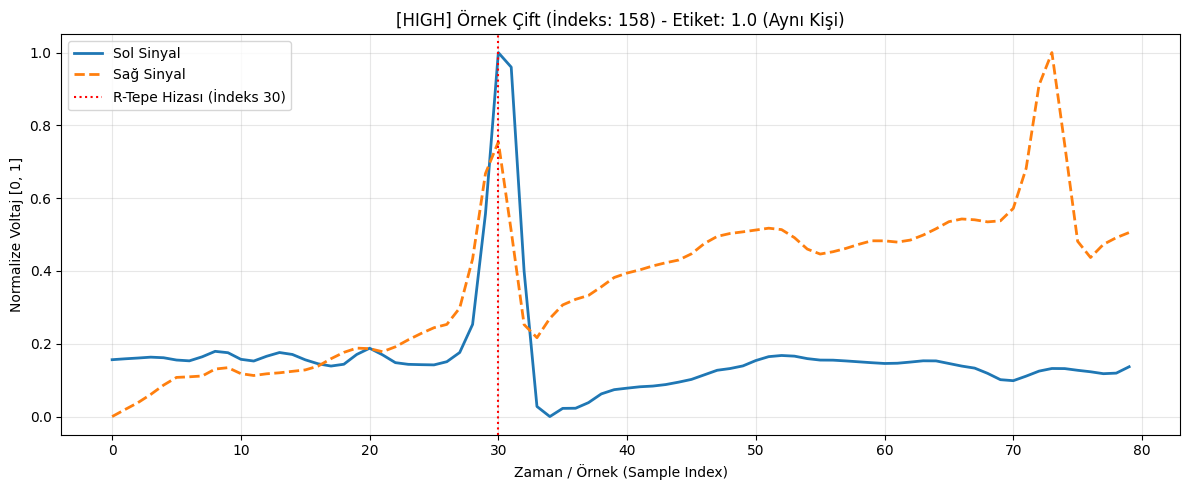

In [ ]:
TIER_TO_VISUALIZE = "high"  # "high" veya "medium" seç

tier_dir = os.path.join(OUTPUT_DIR, TIER_TO_VISUALIZE)
X_left_loaded = np.load(os.path.join(tier_dir, f"X_{TIER_TO_VISUALIZE}_left.npy"))
X_right_loaded = np.load(os.path.join(tier_dir, f"X_{TIER_TO_VISUALIZE}_right.npy"))
y_loaded = np.load(os.path.join(tier_dir, f"y_{TIER_TO_VISUALIZE}.npy"))

print(f"=== VERİ DOĞRULAMA RAPORU ({TIER_TO_VISUALIZE.upper()}) ===")
print(f"Yüklenen X_left Şekli : {X_left_loaded.shape}")
print(f"Yüklenen X_right Şekli: {X_right_loaded.shape}")
print(f"Yüklenen y (Etiket) Şekli: {y_loaded.shape}")

random_idx = np.random.randint(0, len(y_loaded))
sample_left = X_left_loaded[random_idx]
sample_right = X_right_loaded[random_idx]
label = y_loaded[random_idx]

plt.figure(figsize=(12, 5))
plt.plot(sample_left, label='Sol Sinyal', color='#1f77b4', linewidth=2)
plt.plot(sample_right, label='Sağ Sinyal', color='#ff7f0e', linewidth=2, linestyle='--')
plt.axvline(x=30, color='red', linestyle=':', label='R-Tepe Hizası (İndeks 30)')
plt.title(f"[{TIER_TO_VISUALIZE.upper()}] Örnek Çift (İndeks: {random_idx}) - Etiket: {label} "
          f"({'Aynı Kişi' if label == 1.0 else 'Farklı Kişi'})")
plt.xlabel("Zaman / Örnek (Sample Index)")
plt.ylabel("Normalize Voltaj [0, 1]")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Örneklem Kalite Skoru Hesaplanıyor: 100%|██████████| 300/300 [01:24<00:00,  3.57it/s]


Toplam işlenen örnek: 300 / 300

--- np.nanmean ile (şu an kullandığın yöntem) ---
Ortalama: 0.629 | Medyan: 0.632
>= 0.75 (high) oranı: 3.3%
>= 0.50 (medium+) oranı: 96.0%

--- np.nanmedian ile (alternatif, outlier'a dayanıklı) ---
Ortalama: 0.703 | Medyan: 0.717
>= 0.75 (high) oranı: 33.3%
>= 0.50 (medium+) oranı: 96.3%


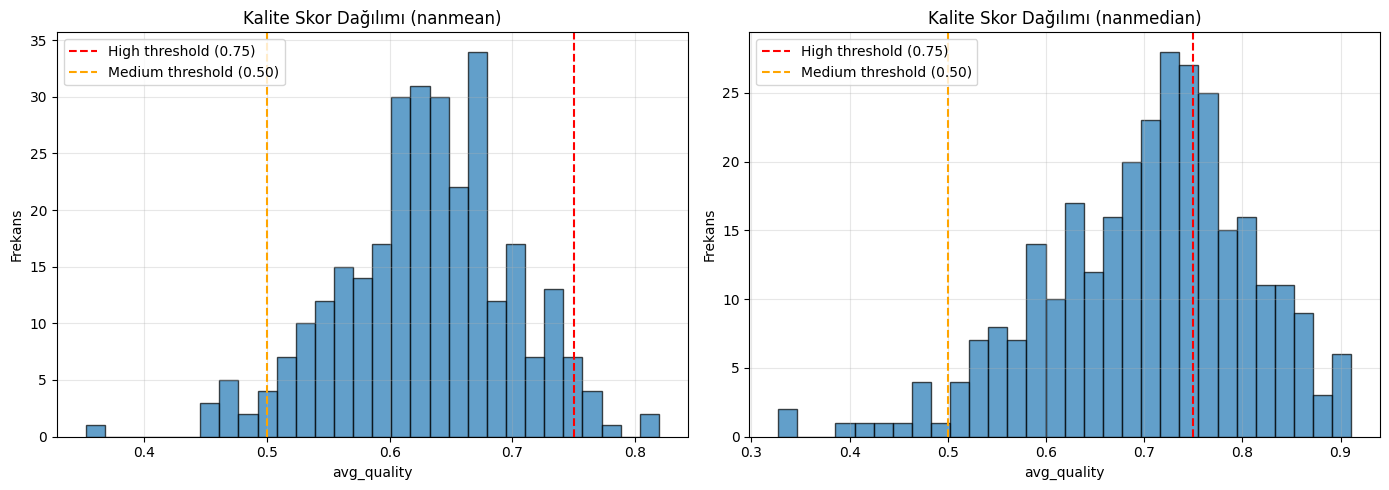

In [ ]:

def get_quality_score_only(row_data):
    """Sadece kalite skorunu hesaplayıp döndüren hafif versiyon (segmentasyon/normalizasyon yok)."""
    try:
        idx, row = row_data
        l_file = row['left_filename']
        r_file = row['right_filename']

        if not l_file.startswith('records100/'): l_file = os.path.join('records100', l_file)
        if not r_file.startswith('records100/'): r_file = os.path.join('records100', r_file)

        left_path = os.path.join(BASE_DIR, l_file)
        right_path = os.path.join(BASE_DIR, r_file)

        signal_left, _ = wfdb.rdsamp(left_path, channels=[0])
        signal_right, _ = wfdb.rdsamp(right_path, channels=[0])

        clean_left = nk.ecg_clean(signal_left.flatten(), sampling_rate=100, method="neurokit")
        clean_right = nk.ecg_clean(signal_right.flatten(), sampling_rate=100, method="neurokit")

        raw_q_left = np.atleast_1d(nk.ecg_quality(clean_left, sampling_rate=100, method="averageQRS"))
        raw_q_right = np.atleast_1d(nk.ecg_quality(clean_right, sampling_rate=100, method="averageQRS"))

        q_left_mean = float(np.nanmean(raw_q_left))
        q_right_mean = float(np.nanmean(raw_q_right))
        q_left_median = float(np.nanmedian(raw_q_left))
        q_right_median = float(np.nanmedian(raw_q_right))

        return {
            "avg_quality_mean": np.nanmean([q_left_mean, q_right_mean]),
            "avg_quality_median": np.nanmean([q_left_median, q_right_median]),
        }
    except Exception:
        return None


# --- Örneklem üzerinde çalıştır (tüm dataset değil, hızlı olsun) ---
SAMPLE_SIZE = 300
sample_df = all_pairs_df.sample(n=SAMPLE_SIZE, random_state=42)

sample_scores = []
with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [executor.submit(get_quality_score_only, row_data) for row_data in sample_df.iterrows()]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Örneklem Kalite Skoru Hesaplanıyor"):
        result = f.result()
        if result is not None:
            sample_scores.append(result)

mean_scores = [s["avg_quality_mean"] for s in sample_scores]
median_scores = [s["avg_quality_median"] for s in sample_scores]

print(f"Toplam işlenen örnek: {len(sample_scores)} / {SAMPLE_SIZE}")
print(f"\n--- np.nanmean ile (şu an kullandığın yöntem) ---")
print(f"Ortalama: {np.mean(mean_scores):.3f} | Medyan: {np.median(mean_scores):.3f}")
print(f">= 0.75 (high) oranı: {np.mean(np.array(mean_scores) >= 0.75)*100:.1f}%")
print(f">= 0.50 (medium+) oranı: {np.mean(np.array(mean_scores) >= 0.50)*100:.1f}%")

print(f"\n--- np.nanmedian ile (alternatif, outlier'a dayanıklı) ---")
print(f"Ortalama: {np.mean(median_scores):.3f} | Medyan: {np.median(median_scores):.3f}")
print(f">= 0.75 (high) oranı: {np.mean(np.array(median_scores) >= 0.75)*100:.1f}%")
print(f">= 0.50 (medium+) oranı: {np.mean(np.array(median_scores) >= 0.50)*100:.1f}%")

# --- Histogram: iki yöntemi yan yana karşılaştır ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, scores, title in zip(axes, [mean_scores, median_scores], ["nanmean", "nanmedian"]):
    ax.hist(scores, bins=30, color='#1f77b4', alpha=0.7, edgecolor='black')
    ax.axvline(x=0.75, color='red', linestyle='--', label='High threshold (0.75)')
    ax.axvline(x=0.50, color='orange', linestyle='--', label='Medium threshold (0.50)')
    ax.set_title(f"Kalite Skor Dağılımı ({title})")
    ax.set_xlabel("avg_quality")
    ax.set_ylabel("Frekans")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()